In [1]:
# Import libraries
import os
from functools import partial
import sys
import subprocess
import argparse
import itertools
from functools import partial
from collections import defaultdict, Counter
import time
import matplotlib.ticker as mtick
import matplotlib.pyplot as plt
import numpy as np
import matplotlib
import warnings

In [2]:
# Configuration and Global Variables
warnings.filterwarnings("ignore")
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
OUTPUT_PATH = "./graphs/"
MARKERS = [".", "o", "v", "p", "*", "s", "x", "2","D"]
STR_WHERE_COMPANY_DATA_STARTS_IN_OUTPUT = "Companys and Market Share (cleaned)"
DEFAULT_COLORS = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']

date_to_index = {
    "2017-06-08": 0,
    "2017-12-05": 1,
    "2018-06-05": 2,
    "2018-12-04": 3,
    "2019-06-06": 4,
    "2019-12-10": 5,
    "2020-06-09": 6,
    "2020-12-05": 7,
    "2021-06-08": 8,
}

index_to_date = {v:k for k,v in date_to_index.items()}

# For iterating over dates
INDEX = 0

In [3]:
# Helper funcs
def get_next_color(comp, colors):
    if comp == "Google":
        colors.remove('#1f77b4')
        return '#1f77b4'
    if comp == "Microsoft":
        colors.remove('#ff7f0e')
        return '#ff7f0e'
    if comp == "Mimecast":
        colors.remove('#2ca02c')
        return '#2ca02c'
    if comp == "ProofPoint":
        colors.remove('#d62728')
        return '#d62728'
    if comp == "Total":
        colors.remove('#8c564b')
        return '#8c564b'
    if comp == "Self":
        colors.remove('#e377c2')
        return '#e377c2'
    if comp == 'Yandex' or comp == 'Barracuda' or comp == 'GoDaddy':
        colors.remove('#9467bd')
        return '#9467bd'
    return colors.pop(0)

def get_next_marker(comp, markers):
    if comp == "Google":
        markers.remove('.')
        return '.'
    if comp == "Microsoft":
        markers.remove('o')
        return 'o'
    if comp == "Mimecast":
        markers.remove('v')
        return 'v'
    if comp == "ProofPoint":
        markers.remove('p')
        return 'p'
    if comp == "Total":
        markers.remove('D')
        return 'D'
    if comp == "Self":
        markers.remove('s')
        return 's'
    if comp == 'Yandex' or comp == 'Barracuda' or comp == 'GoDaddy':
        markers.remove('x')
        return 'x'
    return markers.pop(0)

# Read processed output from the data folder
def read_top_company_data(mx_type, date_specified, topn, ttl_num_domains, version_info):
    output_file_name = "./data/cr_output_cr_{}_old_certs_{}_{}".format(mx_type, date_specified, version_info)
    dict_provider_to_size = {}
    domain_stats = {}
    top_stats = {}
    record = False
    c = 0
    groundtruth = 0


    real_topn_stats = []
    with open(output_file_name) as f:
        for line in f:
            line = line.strip()
            if line == "":
                continue

            if "with responding smtp server" in line:
                groundtruth += eval(line)[1]
                continue

            if line.startswith(STR_WHERE_COMPANY_DATA_STARTS_IN_OUTPUT):
                record = True
            elif record == True:
                try:
                    r = eval(line)
                    name, coverage, ases = r[0], r[1][1], r[1][-1]
                      # strip is wrong
                    #name=name[len("ID:"):].strip()
                    #coverage = float(coverage.strip("Coverage:"))
                    #print(name)
                    #break
                    ases = ases - set([None])
                    dict_provider_to_size[name] = float(coverage)
                    top_stats[name] = (coverage)
                    if len(real_topn_stats) <= topn:
                        real_topn_stats.append((name,coverage))
                    
                except:
                    #pass
                    #print(line)
                    raise
    
    ttl = sum(i for i in dict_provider_to_size.values())
    top_stats['total_good_id'] = groundtruth
    top_stats['total_domains'] = ttl_num_domains[mx_type][date_to_index[date_specified]]
    return top_stats, real_topn_stats

def forward(y, mx_type):
    if mx_type == "common":
        ttl = 93538
    elif mx_type == "gov_common":
        ttl = 3496
    elif mx_type == "com_common":
        ttl = 580537 
    else:
        raise Exception("Bug")
    
    return y * 100.0 / ttl 

def inverse(y, mx_type):
    if mx_type == "common":
        ttl = 93538
    elif mx_type == "gov_common":
        ttl = 3496
    elif mx_type == "com_common":
        ttl = 580537 
    else:
        raise Exception("Bug")

    return y * ttl / 100.0

In [4]:
def vis_result_top_company(mx_type, dates, topn, ttl_num_domains, version_info):
    global INDEX, FIG, AXES, DEFAULT_COLORS
    colors = [i for i in DEFAULT_COLORS]
    markers = [i for i in MARKERS]
    
    if "alexa" not in mx_type and "common" not in mx_type and "com_common" not in mx_type:
        return 

    output = []
    all_stats = []

    for date_specified in dates:
        top_stats,real_topn_stats = read_top_company_data(mx_type, date_specified, topn, ttl_num_domains, version_info)
        if date_specified == dates[-1]:
            recent_real_topn_stats = real_topn_stats
        all_stats.append(top_stats)

    # Special Handle For EIG
    if mx_type != "com_common":
        comps = [i[0] for i in recent_real_topn_stats][:topn]
    else:
        tmp = [i[0] for i in recent_real_topn_stats][:6]
        comps = tmp[:4] + tmp[5:6]

    print("Visualzing Top Companys")
    print("Top Companies", comps)
    print('>>> Generating Graph for Top Companies in {}\n'.format(mx_type))

    ### Get # of Domains using Self-Hosted servers (Hardcoded)
    if mx_type == "common":
        domains_using_self_hosted_servers = [10898.633333333335, 10642.072222222223, 10259.93888888889, 9695.683333333332, 9063.133333333335, 9208.916666666668, 8958.105555555558, 8199.410256410258, 7407.310256410256]
    elif mx_type == "gov_common":
        domains_using_self_hosted_servers = [356.0, 343.0, 305.0, 301.0, 279.0, 215.0, 189.0]
    else:
        domains_using_self_hosted_servers = [3116.833333333333, 2927.833333333333, 2792.333333333333, 2657.1666666666665, 2382.6666666666665, 2316.1666666666665, 2246.1666666666665, 2017.5, 1836.3333333333333]

    

    ps = []
    ypoints_ttl = [0] * len(dates)

    func_forward = partial(forward, mx_type = mx_type)
    func_inverse = partial(inverse, mx_type = mx_type)

    r, c = INDEX//3, INDEX%3
    ax = AXES[r, c]
    INDEX += 1

    for c_i, comp in enumerate(comps):
        if len(dates) == 7:
            xpoints = [index_to_date[i+2][:7] for i in range(len(dates))]
        else:
            xpoints = [index_to_date[i][:7] for i in range(len(dates))]
        ypoints = []
        for i in range(len(dates)):
            d = dates[i]
            data = all_stats[i]
            if comp in data:
                num = data[comp]
            else:
                if comp == "Mimecast":
                    num = 0
                    num += data['mimecast.com'] if 'mimecast.com' in data else 0
                    num += data['mimecast.co.za'] if 'mimecast.co.za' in data else 0
                    num += data['mimecast-offshore.com'] if 'mimecast-offshore.com' in data else 0
                else:
                    print(comp)
                    raise Exception("Nope")
            ypoints.append(num)
            ypoints_ttl[i] += num
        ypoints = np.array(ypoints)
        # print(xpoints, ypoints, [func_forward(ypoint) for ypoint in ypoints])
        p, = ax.plot(xpoints, ypoints, marker = get_next_marker(comp,markers), color = get_next_color(comp,colors))
        # print(colors)
        ps.append(p)
    
    # print(xpoints, ypoints_ttl, [func_forward(ypoint_ttl) for ypoint_ttl in ypoints_ttl])
    p, = ax.plot(xpoints, ypoints_ttl, marker = get_next_marker("Total",markers), color=get_next_color("Total",colors))
    ps.append(p)

    # print(xpoints, domains_using_self_hosted_servers, [func_forward(domain_using_self_hosted_servers) for domain_using_self_hosted_servers in domains_using_self_hosted_servers])
    p, = ax.plot(xpoints, domains_using_self_hosted_servers, marker = get_next_marker("Self",markers), color=get_next_color("Self",colors))
    ps.append(p)

    graph_name = 'top5_comapny_{}.pdf'.format(mx_type)
    #ax.set_ylabel('Number of domains')
    #ax.set_xlabel('Dates')

    secax = ax.secondary_yaxis('right', functions=(func_forward, func_inverse))
    #secax.set_ylabel('Percentage of domains')
    secax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))


    # ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))

    if mx_type == "common":
        ax.legend(["Google", "Microsoft", "Yandex", "ProofPoint", "Mimecast" ,"Top5 Total","Self-Hosted"],loc="upper right", bbox_to_anchor=(1,0.92), prop={'size': 12})
    elif mx_type == 'com_common':
        ax.legend(["GoDaddy", "Google", "Microsoft", "UnitedInternet", "OVH" ,"Top5 Total","Self-Hosted"],loc="upper right", bbox_to_anchor=(1,0.94), prop={'size': 12})
    elif mx_type == "gov_common":
        ax.legend(["Microsoft", "Google", "Barracuda", "ProofPoint", "Mimecast" ,"Top5 Total","Self-Hosted"],loc="upper right", bbox_to_anchor=(1,0.894), prop={'size': 12})
    else:
        raise Exception("WTF")

    # print("\n",graph_name)
    if r == 2:
        # print("Xpoints:", xpoints)
        #ax.set_xticks(np.arange(len(["2017-06","2017-12"] + xpoints)))
        if len(xpoints) == 7:
            ax.set_xticklabels(["2017-06","2017-12"] + xpoints,rotation=45, fontsize = 18)
        else:
            ax.set_xticklabels(xpoints,rotation=45, fontsize = 18)
    else:
        # ax.set_xticklabels([],rotation=45)
        if len(xpoints) == 7:
            ax.set_xticklabels(["2017-06","2017-12"] + xpoints,rotation=45, fontsize = 18)
        else:
            ax.set_xticklabels(xpoints,rotation=45, fontsize = 18)

    ax.grid(True)
    #ax.text(0.05, 0.05, "{} in {}".format("Top Companies", mx_type))
    
    idx_letter =  chr(ord("a") + INDEX - 1)
    if mx_type == "common":
        mx_type_name = "Alexa"
    elif mx_type == "gov_common":
        mx_type_name = "GOV"
    else:
        mx_type_name = "COM"

    ax.set_title("({}) {} in {}".format(idx_letter, "Top Companies", mx_type_name), fontweight='bold', fontsize=16)

    for tick in ax.yaxis.get_major_ticks():
        tick.label.set_fontsize(12)
    secax.tick_params(axis="y", labelsize=12)

    print('\n\n')

In [5]:
def vis_result_secure_services(mx_type, dates, topn, ttl_num_domains, version_info):
    global INDEX, FIG, AXES
    all_stats= []
    for date_specified in dates:
        #print(mx_type, date_specified)
        top_stats,real_topn_stats = read_top_company_data(mx_type, date_specified, topn, ttl_num_domains, version_info)
        if date_specified == dates[-1]:
            recent_real_topn_stats = real_topn_stats
        #print(top_stats)
        all_stats.append(top_stats)

    
    ps = []
    ypoints_ttl = [0] * len(dates)

    comps = ['ProofPoint','Mimecast','Barracuda','Cisco Ironport','AppRiver']

    print("Visualzing Top Security Companys")
    print("Top Security Companies", comps)
    print('>>> Generating Graph for Top Security Companies in {}\n'.format(mx_type))

    
    r, c = INDEX//3, INDEX%3
    ax = AXES[r, c]
    INDEX += 1
    
    for c_i, comp in enumerate(comps):
        if len(dates) == 7:
            xpoints = [index_to_date[i+2][:7] for i in range(len(dates))]
        else:
            xpoints = [index_to_date[i][:7] for i in range(len(dates))]
        ypoints = []
        for i in range(len(dates)):
            d = dates[i]
            data = all_stats[i]
            if comp in data:
                num = data[comp]
            else:
                if comp == "Mimecast":
                    num = 0
                    num += data['mimecast.com'] if 'mimecast.com' in data else 0
                    num += data['mimecast.co.za'] if 'mimecast.co.za' in data else 0
                    num += data['mimecast-offshore.com'] if 'mimecast-offshore.com' in data else 0
                elif comp == "ProofPoint":
                    num = 0
                    num += data["pphosted.com"] if "pphosted.com" in data else 0
                    num += data["ppe-hosted.com"] if "ppe-hosted.com" in data else 0
                    num += data["ppops.net"] if "ppops.net" in data else 0
                    num += data["gpphosted.com"] if "gpphosted.com" in data else 0
                elif comp == "AppRiver":
                    num = 0
                    num += data['appriver.com'] if 'appriver.com' in data else 0
                    num += data['arsmtp.com'] if 'arsmtp.com' in data else 0
                    num += data['mimecast-offshore.com'] if 'mimecast-offshore.com' in data else 0
                elif comp == "Barracuda":
                    num = 0
                    num += data['barracudanetworks.com'] if 'barracudanetworks.com' in data else 0
                    num += data['barracuda.com'] if 'barracuda.com' in data else 0
                elif comp == "Cisco Ironport":
                    num = 0
                    num += data['iphmx.com'] if 'iphmx.com' in data else 0
                    num += data['Cisco'] if 'Cisco' in data else 0
                else:
                    raise Exception("Nope")
            ypoints.append(num)
            ypoints_ttl[i] += num
            
            # --- NEW SECTION: print each domain per company/date ---
            print(f"[{mx_type}] {d} → Company: {comp}")
            for domain, val in data.items():
                if comp.lower() in domain.lower():
                    print(f"    Domain: {domain} ({val})")
            print()
            # ------------------------------------------------------
            
        ypoints = np.array(ypoints)
        p, = ax.plot(xpoints, ypoints, marker = MARKERS[c_i])
        ps.append(p)
    
    p, = ax.plot(xpoints, ypoints_ttl, marker = MARKERS[-1])
    ps.append(p)


    graph_name = 'selected_security_company_{}.pdf'.format(mx_type)
    #ax.set_ylabel('Number of domains')
    #ax.set_xlabel('Dates')
    if mx_type == "common":
        ax.legend(ps,['ProofPoint','Mimecast','Barracuda','Cisco Ironport','AppRiver',"Total"], loc="upper right", bbox_to_anchor=(1,0.82), prop={'size': 12})
    elif mx_type == "com_common":
        ax.legend(ps,['ProofPoint','Mimecast','Barracuda','Cisco Ironport','AppRiver',"Total"], loc="upper right", bbox_to_anchor=(1,0.82), prop={'size': 12})
    elif mx_type == "gov_common":
        ax.legend(ps,['ProofPoint','Mimecast','Barracuda','Cisco Ironport','AppRiver',"Total"], loc="upper right", bbox_to_anchor=(1,0.815), prop={'size': 12})
    else:
        raise Exception('wtf')
    
    #plt.title('Scores by group and gender')
    #plt.xticks(ind, ('G1', 'G2', 'G3', 'G4', 'G5'))
    #plt.yticks(np.arange(0, 81, 10))
    #plt.legend((p1[0], p2[0]), ('Men', 'Women'))

    func_forward = partial(forward, mx_type = mx_type)
    func_inverse = partial(inverse, mx_type = mx_type)


    secax = ax.secondary_yaxis('right', functions=(func_forward, func_inverse))
    #secax.set_ylabel('Percentage of domains')
    secax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))


    # print("\n",graph_name)
    if r == 2:
        # print("Xpoints:", xpoints)
        if len(xpoints) == 7:
            ax.set_xticklabels(["2017-06","2017-12"] + xpoints,rotation=45, fontsize = 18)
        else:
            ax.set_xticklabels(xpoints,rotation=45, fontsize = 18)
    else:
        # ax.set_xticklabels([],rotation=45)
        if len(xpoints) == 7:
            ax.set_xticklabels(["2017-06","2017-12"] + xpoints,rotation=45, fontsize = 18)
        else:
            ax.set_xticklabels(xpoints,rotation=45, fontsize = 18)
    ax.grid(True)
    
    idx_letter =  chr(ord("a") + INDEX - 1)
    if mx_type == "common":
        mx_type_name = "Alexa"
    elif mx_type == "gov_common":
        mx_type_name = "GOV"
    else:
        mx_type_name = "COM"

    ax.set_title("({}) {} in {}".format(idx_letter, "Popular E-mail Security Companies", mx_type_name), fontweight='bold', fontsize=16)

    for tick in ax.yaxis.get_major_ticks():
        tick.label.set_fontsize(12)
    #for tick in secax.yaxis.get_major_ticks():
        #tick.label.set_fontsize(12)
    secax.tick_params(axis="y", labelsize=12)

    #plt.savefig('{}/{}'.format(OUTPUT_PATH,graph_name), dpi = 800)
    #plt.clf()
    print('\n\n')

In [6]:
def vis_result_webhosting_services(mx_type, dates, topn, ttl_num_domains, version_info):
    global INDEX, FIG, AXES
    
    all_stats= []
    for date_specified in dates:
        #print(mx_type, date_specified)
        top_stats,real_topn_stats = read_top_company_data(mx_type, date_specified, topn, ttl_num_domains, version_info)
        if date_specified == dates[-1]:
            recent_real_topn_stats = real_topn_stats
        #print(top_stats)
        all_stats.append(top_stats)

    
    ps = []
    ypoints_ttl = [0] * len(dates)

    r, c = INDEX//3, INDEX%3
    ax = AXES[r, c]
    INDEX += 1

    comps = ['GoDaddy','OVH','UnitedInternet','Ukraine.ua','NameCheap']
    print("Visualzing Top Web Hosting Companys")
    print("Top Hosting Companies", comps)
    print('>>> Generating Graph for Top Hosting Companies in {}\n'.format(mx_type))


    
    for c_i, comp in enumerate(comps):
        if len(dates) == 7:
            xpoints = [index_to_date[i+2][:7] for i in range(len(dates))]
        else:
            xpoints = [index_to_date[i][:7] for i in range(len(dates))]
        ypoints = []
        for i in range(len(dates)):
            d = dates[i]
            data = all_stats[i]
            if comp in data:
                num = data[comp]
            else:
                if comp == "GoDaddy":
                    num = 0
                    for k in ["secureserver.net","mailcore.me","hosteurope.de","extendcp.co.uk","ispgateway.de"]:
                        if k in data:
                            num += data[k]
                elif comp == "OVH":
                    num = 0
                    for k in ["ovh.net","ovh.ca"]:
                        if k in data:
                            num += data[k]
                elif comp == "UnitedInternet":
                    num = 0
                    for k in ["kundenserver.de","perfora.net","1and1.com","mail.com","livemail.co.uk","web.de","gmx.net"]:
                        if k in data:
                            num += data[k]
                elif comp == "NameCheap":
                    num = 0
                    for k in ["privateemail.com","namecheap.tech","registrar-servers.com","web-hosting.com","namecheaphosting.com","jellyfish.systems"]:
                        if k in data:
                            num += data[k]
                elif comp == "Ukraine.ua":
                    num = 0
                    for k in ["default-host.net","ukraine.com.ua","vps-ukraine.com.ua","vps-default-host.net",]:
                        if k in data:
                            num += data[k]
                else:
                    raise Exception("Nope")
            ypoints.append(num)
            ypoints_ttl[i] += num
        ypoints = np.array(ypoints)
        # print(xpoints, ypoints)
        p, = ax.plot(xpoints, ypoints, marker = MARKERS[c_i])
        ps.append(p)
    
    p, = ax.plot(xpoints, ypoints_ttl, marker = MARKERS[-1])
    ps.append(p)

    func_forward = partial(forward, mx_type = mx_type)
    func_inverse = partial(inverse, mx_type = mx_type)

    secax = ax.secondary_yaxis('right', functions=(func_forward, func_inverse))
    secax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))


    graph_name = 'selected_webhosting_company_{}.pdf'.format(mx_type)
    if mx_type == "common":
        ax.legend(ps,comps+["Total"], loc="upper right", bbox_to_anchor=(1,0.75), prop={'size': 12})
    elif mx_type == "com_common":
        ax.legend(ps,comps+["Total"], loc="upper right", bbox_to_anchor=(1,0.65), prop={'size': 12})
    elif mx_type == "gov_common":
        ax.legend(ps,comps+["Total"], loc="upper right", bbox_to_anchor=(1,0.47), prop={'size': 12})
    
    
    # print("\n",graph_name)
    if r == 2:
        # print("Xpoints:", xpoints)
        if len(xpoints) == 7:
            ax.set_xticklabels(["2017-06","2017-12"] + xpoints,rotation=45, fontsize = 18)
        else:
            ax.set_xticklabels(xpoints,rotation=45, fontsize = 18)
    else:
        # ax.set_xticklabels([],rotation=45)
        if len(xpoints) == 7:
            ax.set_xticklabels(["2017-06","2017-12"] + xpoints,rotation=45, fontsize = 18)
        else:
            ax.set_xticklabels(xpoints,rotation=45, fontsize = 18)

    ax.grid(True)
    
    idx_letter =  chr(ord("a") + INDEX - 1)
    if mx_type == "common":
        mx_type_name = "Alexa"
    elif mx_type == "gov_common":
        mx_type_name = "GOV"
    else:
        mx_type_name = "COM"
    ax.set_title("({}) {} in {}".format(idx_letter, "Popular Web Hosting Companies", mx_type_name), fontweight='bold', fontsize=16)

    for tick in ax.yaxis.get_major_ticks():
        tick.label.set_fontsize(12)
    secax.tick_params(axis="y", labelsize=12)

    print('\n\n')

Visualzing Top Companys
Top Companies ['Google', 'Microsoft', 'Yandex', 'ProofPoint', 'Mimecast']
>>> Generating Graph for Top Companies in common




Visualzing Top Security Companys
Top Security Companies ['ProofPoint', 'Mimecast', 'Barracuda', 'Cisco Ironport', 'AppRiver']
>>> Generating Graph for Top Security Companies in common

[common] 2017-06-08 → Company: ProofPoint
    Domain: ProofPoint (1255.0)

[common] 2017-12-05 → Company: ProofPoint
    Domain: ProofPoint (1494.0)

[common] 2018-06-05 → Company: ProofPoint
    Domain: ProofPoint (1712.0)

[common] 2018-12-04 → Company: ProofPoint
    Domain: ProofPoint (1952.0)

[common] 2019-06-06 → Company: ProofPoint
    Domain: ProofPoint (2142.666666666667)

[common] 2019-12-10 → Company: ProofPoint
    Domain: ProofPoint (2316.666666666667)

[common] 2020-06-09 → Company: ProofPoint
    Domain: ProofPoint (2478.833333333333)

[common] 2020-12-05 → Company: ProofPoint
    Domain: ProofPoint (2672.5)

[common] 2021-06-08 → Company: 

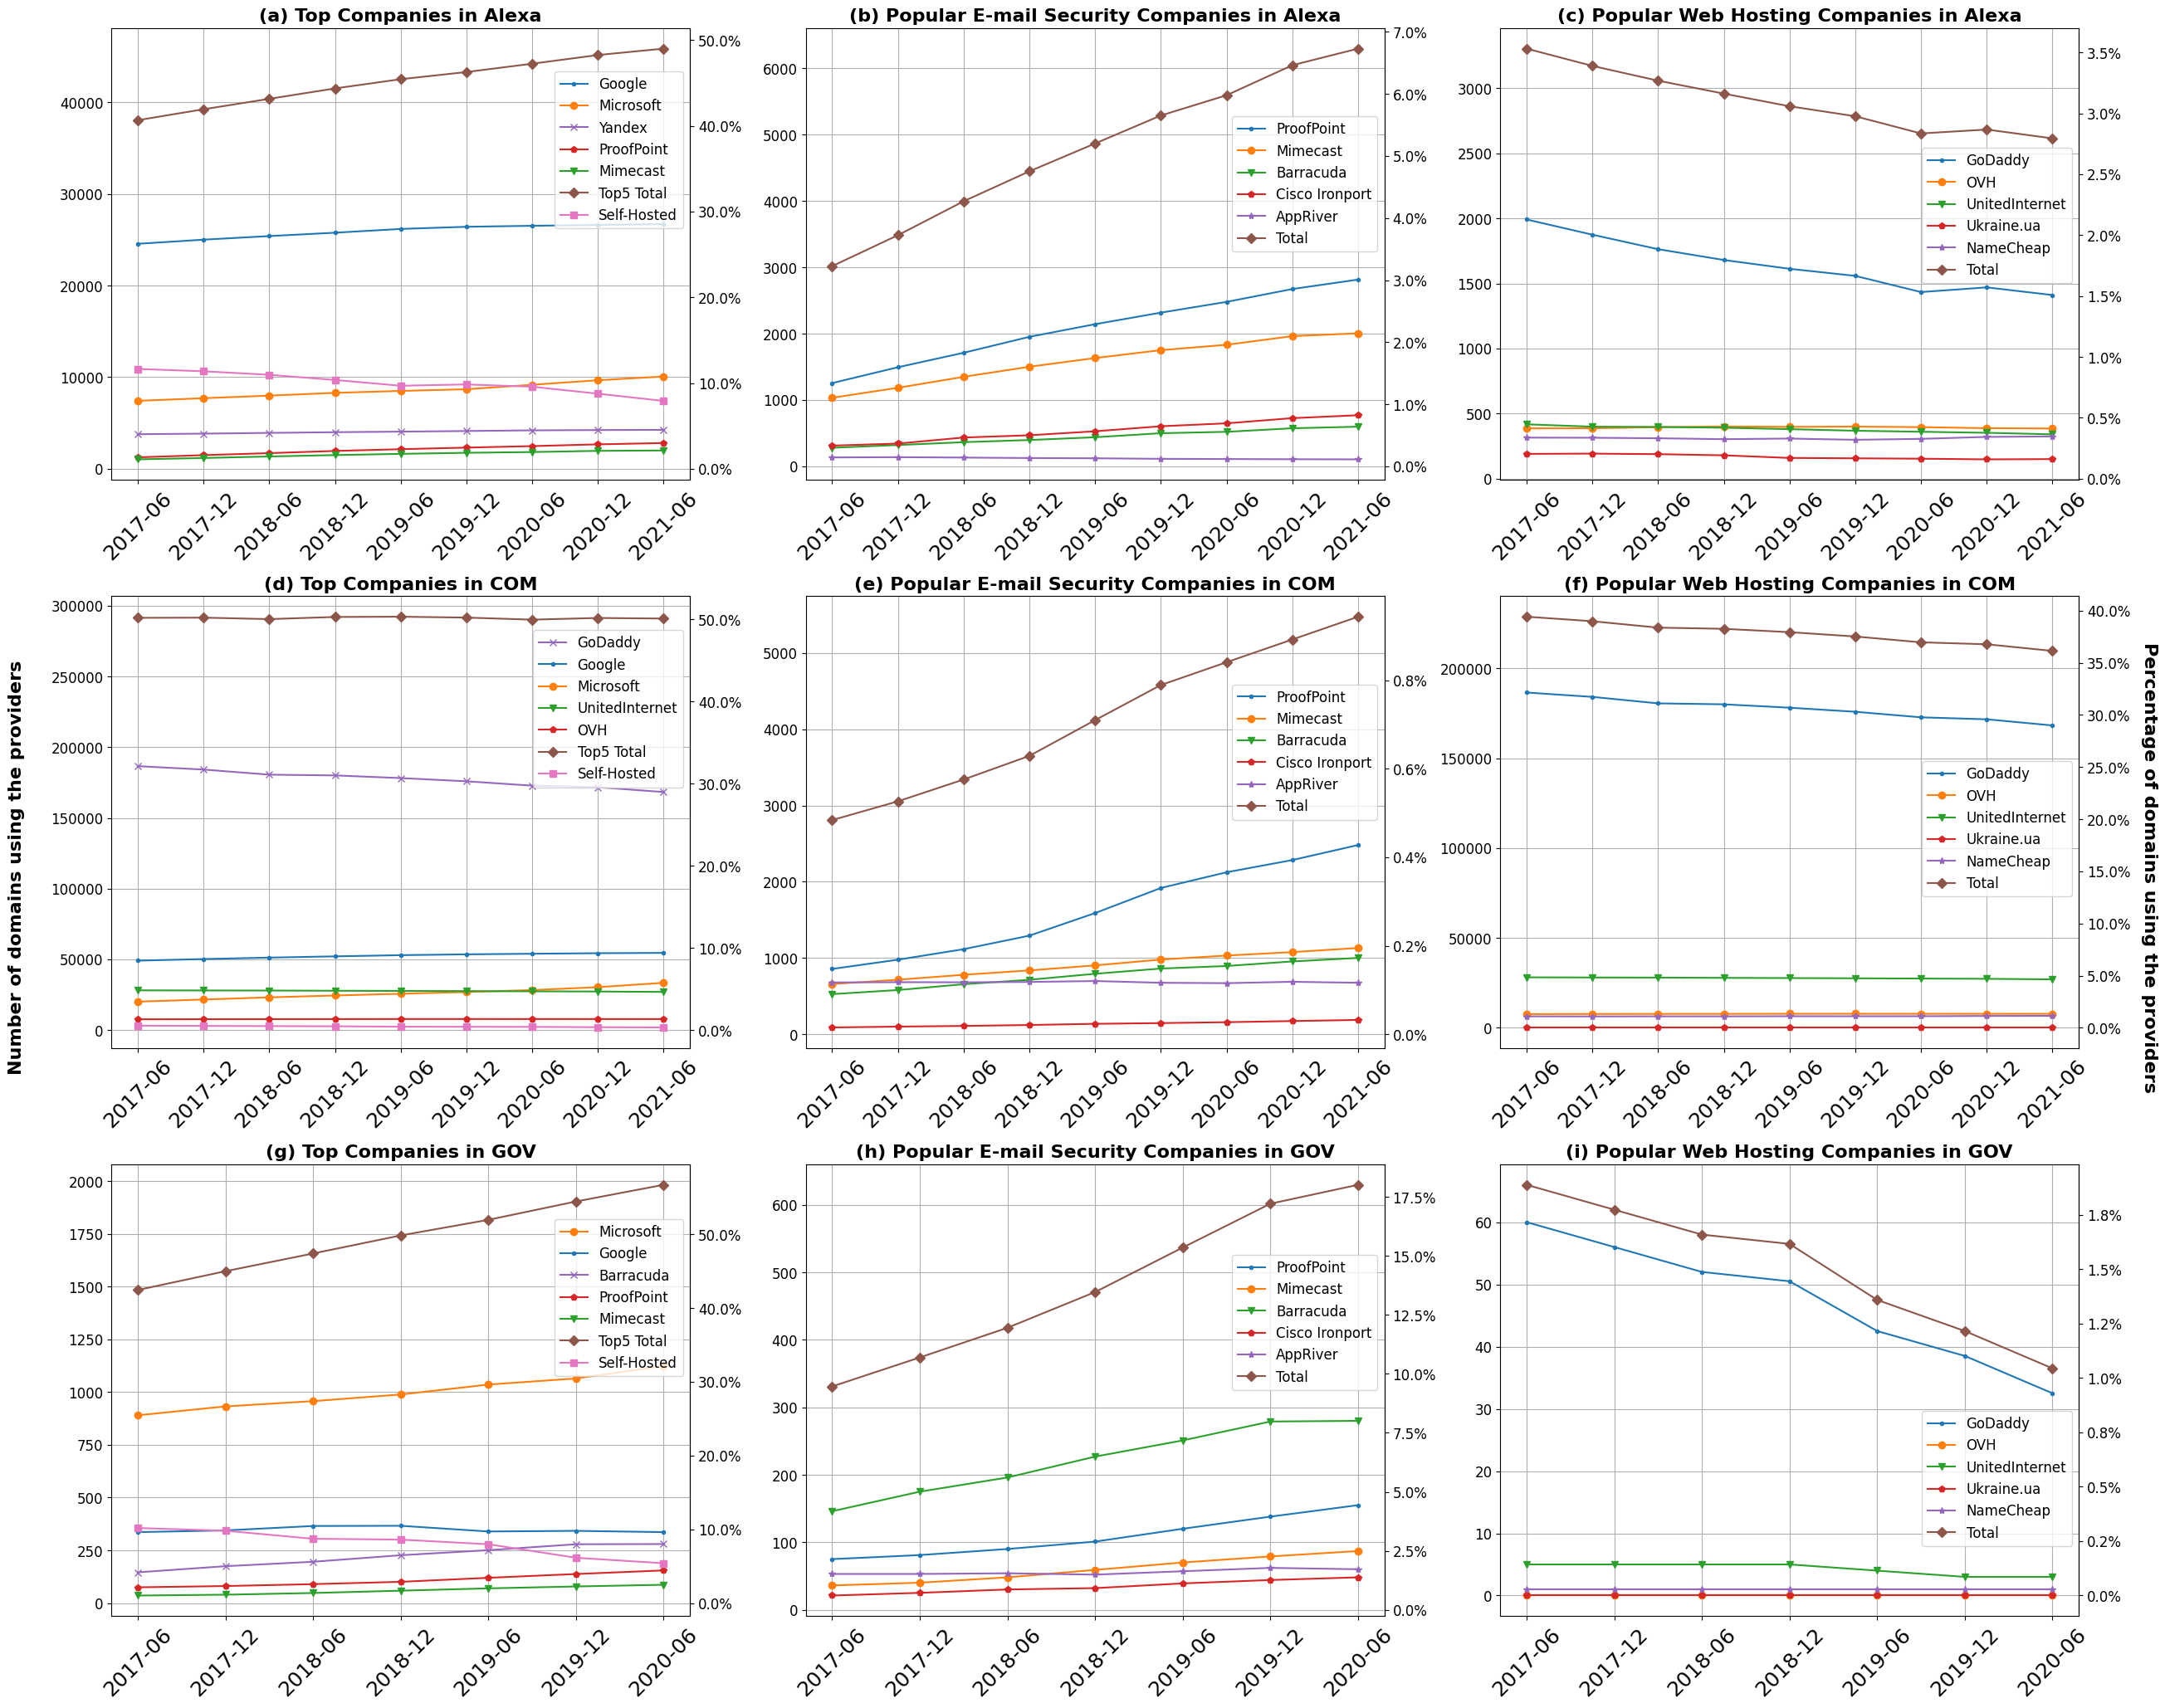

<Figure size 640x480 with 0 Axes>

In [7]:
# Main Functions
FIG, AXES = plt.subplots(3, 3, figsize=(26,21), sharex=False)

def gen_all_graphs(ttl_num_domains, version_info, topn = 5):
    for mx_type, dates in zip(\
        ["common","com_common","gov_common"],\
        [("2017-06-08","2017-12-05","2018-06-05","2018-12-04","2019-06-06","2019-12-10","2020-06-09","2020-12-05","2021-06-08"),\
        ("2017-06-08","2017-12-05","2018-06-05","2018-12-04","2019-06-06","2019-12-10","2020-06-09","2020-12-05","2021-06-08"),\
        ("2018-06-05","2018-12-04","2019-06-06","2019-12-10","2020-06-09","2020-12-05","2021-06-08"),\
        ]):

        vis_result_top_company(mx_type, dates, topn, ttl_num_domains, version_info)
        vis_result_secure_services(mx_type, dates, topn, ttl_num_domains, version_info)
        vis_result_webhosting_services(mx_type, dates, topn, ttl_num_domains, version_info)

if __name__ == "__main__":
    ttl_num_domains = {
    'common': [93538] * 9,
    'com_common': [580537] * 9,
    'gov_common': [3496] * 9,
    }
    
    version_info = "0914"

    gen_all_graphs(ttl_num_domains, version_info)
    plt.tight_layout(rect=[0.015, 0.015, 0.99, 1])
    
    FIG.text(0.001, 0.5, 'Number of domains using the providers', va='center', rotation='vertical', fontweight='bold', fontsize=16)
    FIG.text(0.989, 0.5, 'Percentage of domains using the providers', va='center', rotation=-90, fontweight='bold', fontsize=16)
    plt.savefig('{}/{}'.format(OUTPUT_PATH,"trends_combined.pdf"), format = 'pdf')
    plt.show()
    plt.clf()